Primeiro vamos importar a base montada

In [15]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

path_processed = Path(r"..\data") / "processed"
df = pd.read_csv(path_processed / "fakebr_base.csv", encoding='utf-8')
display(df.head())

,index,par_id,rotulo,texto,autor,link,categoria,data,n_tokens,n_palavras,...,n_pron_sing_1_2,n_pron_plur_1,n_pronomes,pausalidade,n_caracteres,tam_medio_sentenca,tam_medio_palavra,erros_ortograficos,emotividade,diversidade
0,0,1,0,﻿O Podemos decidiu expulsar o deputado federa...,Naira Trindade,http://politica.estadao.com.br/blogs/coluna-do...,politica,13/12/2017,168,148,...,0,0,7,3.33333,761.0,24.6667,5.14189,0.000000,0.134328,0.722973
1,1,1,1,Kátia Abreu diz que vai colocar sua expulsão e...,mrk,https://ceticismopolitico.com/2017/11/30/katia...,politica,2017-11-30,211,185,...,2,0,26,2.00000,815.0,14.2308,4.40541,0.000000,0.263158,0.648649
2,2,2,0,Em evento realizado nesta terça-feira para div...,Estadão Conteúdo,http://esportes.estadao.com.br/noticias/futebo...,sociedade_cotidiano,26/12/2017,349,294,...,0,0,29,2.75000,1477.0,14.7000,5.02381,0.000000,0.325758,0.619048
3,3,2,1,Blog esquerdista dá a entender que reclamar de...,NaN,https://ceticismopolitico.com/2017/11/28/blog-...,sociedade_cotidiano,2017-11-28,356,300,...,0,0,30,3.29412,1321.0,17.6471,4.40333,0.013333,0.277372,0.623333
4,4,3,0,﻿Após o prefeito de Manaus Arthur Virgílio (PS...,Juliana Diógenes,"http://politica.estadao.com.br/noticias/geral,...",politica,26/12/2017,249,204,...,3,0,8,3.00000,1019.0,13.6000,4.99510,0.014706,0.160000,0.627451


Vamos observar como o tamanho do texto e numero de tokens varia com a veracidade e categorias.

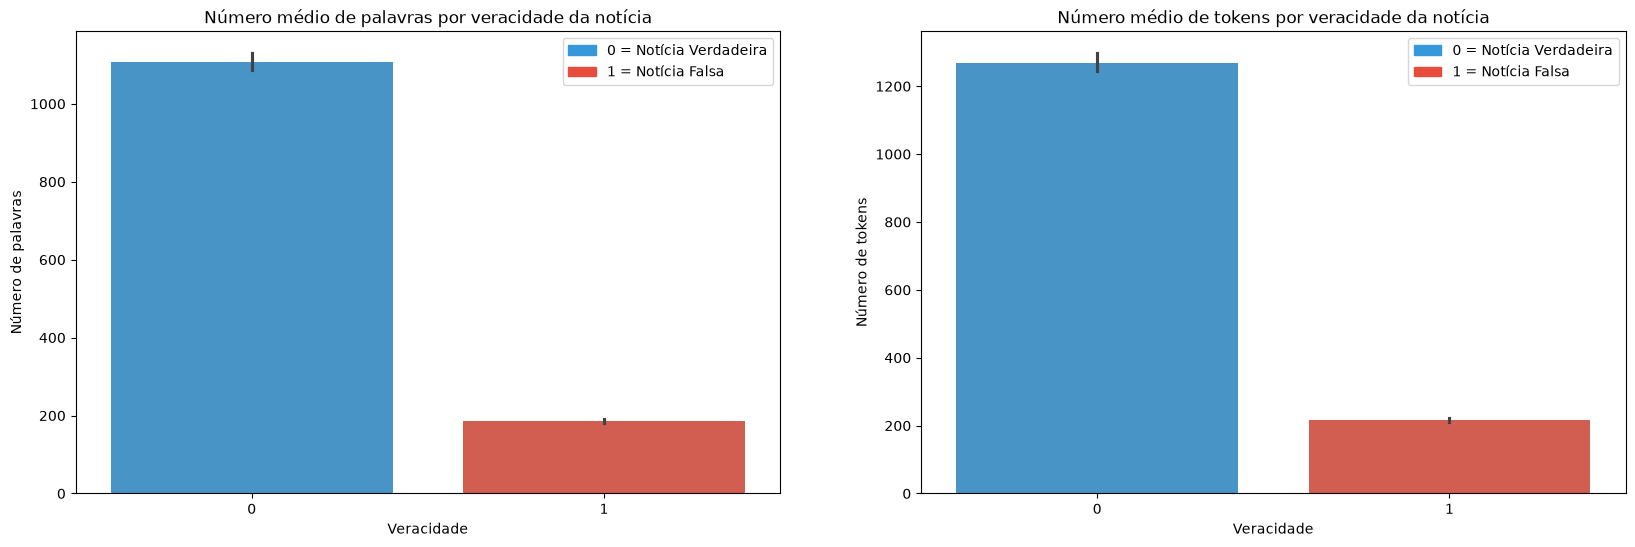

In [46]:
custom_handles = [
    mpatches.Patch(color="#3498db", label="0 = Notícia Verdadeira"),
    mpatches.Patch(color="#e74c3c", label="1 = Notícia Falsa"),
]

palette = {
    0: "#3498db",
    1: "#e74c3c",
}

plt.figure(figsize=(20, 6))

plt.subplot(121)
ax1 = sns.barplot(data=df, x="rotulo", y="n_palavras", legend=False, hue="rotulo", palette=palette)
plt.xlabel("Veracidade")
plt.ylabel("Número de palavras")
plt.title("Número médio de palavras por veracidade da notícia")
ax1.legend(handles=custom_handles, frameon=True)

plt.subplot(122)
ax2 = sns.barplot(data=df, x="rotulo", y="n_tokens", legend=False, hue="rotulo", palette=palette)
plt.xlabel("Veracidade")
plt.ylabel("Número de tokens")
plt.title("Número médio de tokens por veracidade da notícia")
ax2.legend(handles=custom_handles, frameon=True)
plt.show()


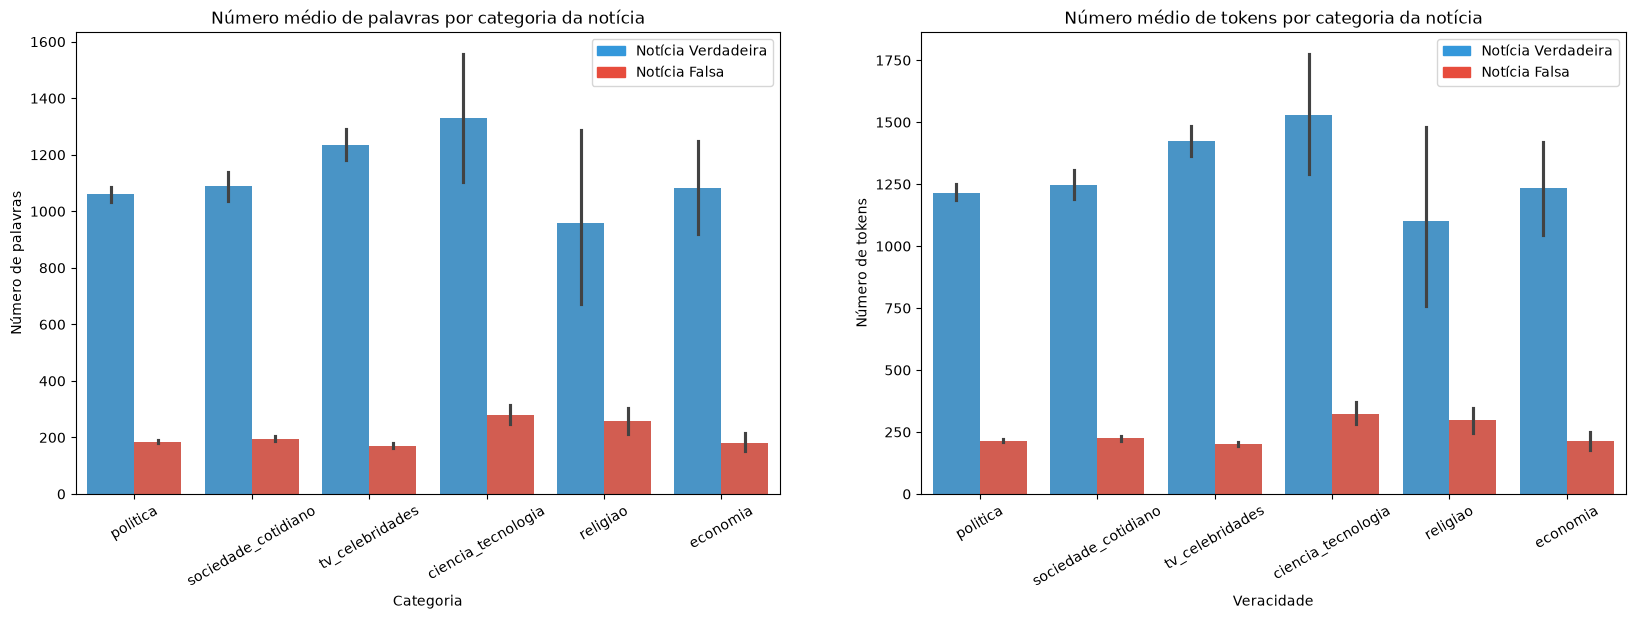

In [48]:
custom_handles = [
    mpatches.Patch(color="#3498db", label="Notícia Verdadeira"),
    mpatches.Patch(color="#e74c3c", label="Notícia Falsa"),
]

plt.figure(figsize=(20, 6))

plt.subplot(121)
ax3 = sns.barplot(data=df, x="categoria", y="n_palavras", legend=False, hue="rotulo", palette=palette)
plt.xlabel("Categoria")
plt.ylabel("Número de palavras")
plt.title("Número médio de palavras por categoria da notícia")
plt.xticks(rotation=30)
ax3.legend(handles=custom_handles, frameon=True)

plt.subplot(122)
ax4 = sns.barplot(data=df, x="categoria", y="n_tokens", legend=False, hue="rotulo", palette=palette)
plt.xlabel("Veracidade")
plt.ylabel("Número de tokens")
plt.title("Número médio de tokens por categoria da notícia")
plt.xticks(rotation=30)
ax4.legend(handles=custom_handles, frameon=True)
plt.show()

Vamos investigar se existe alguma relação entre pausalidade, erros_ortograficos, emotividade, diversidade e  rotulo e  rotulo

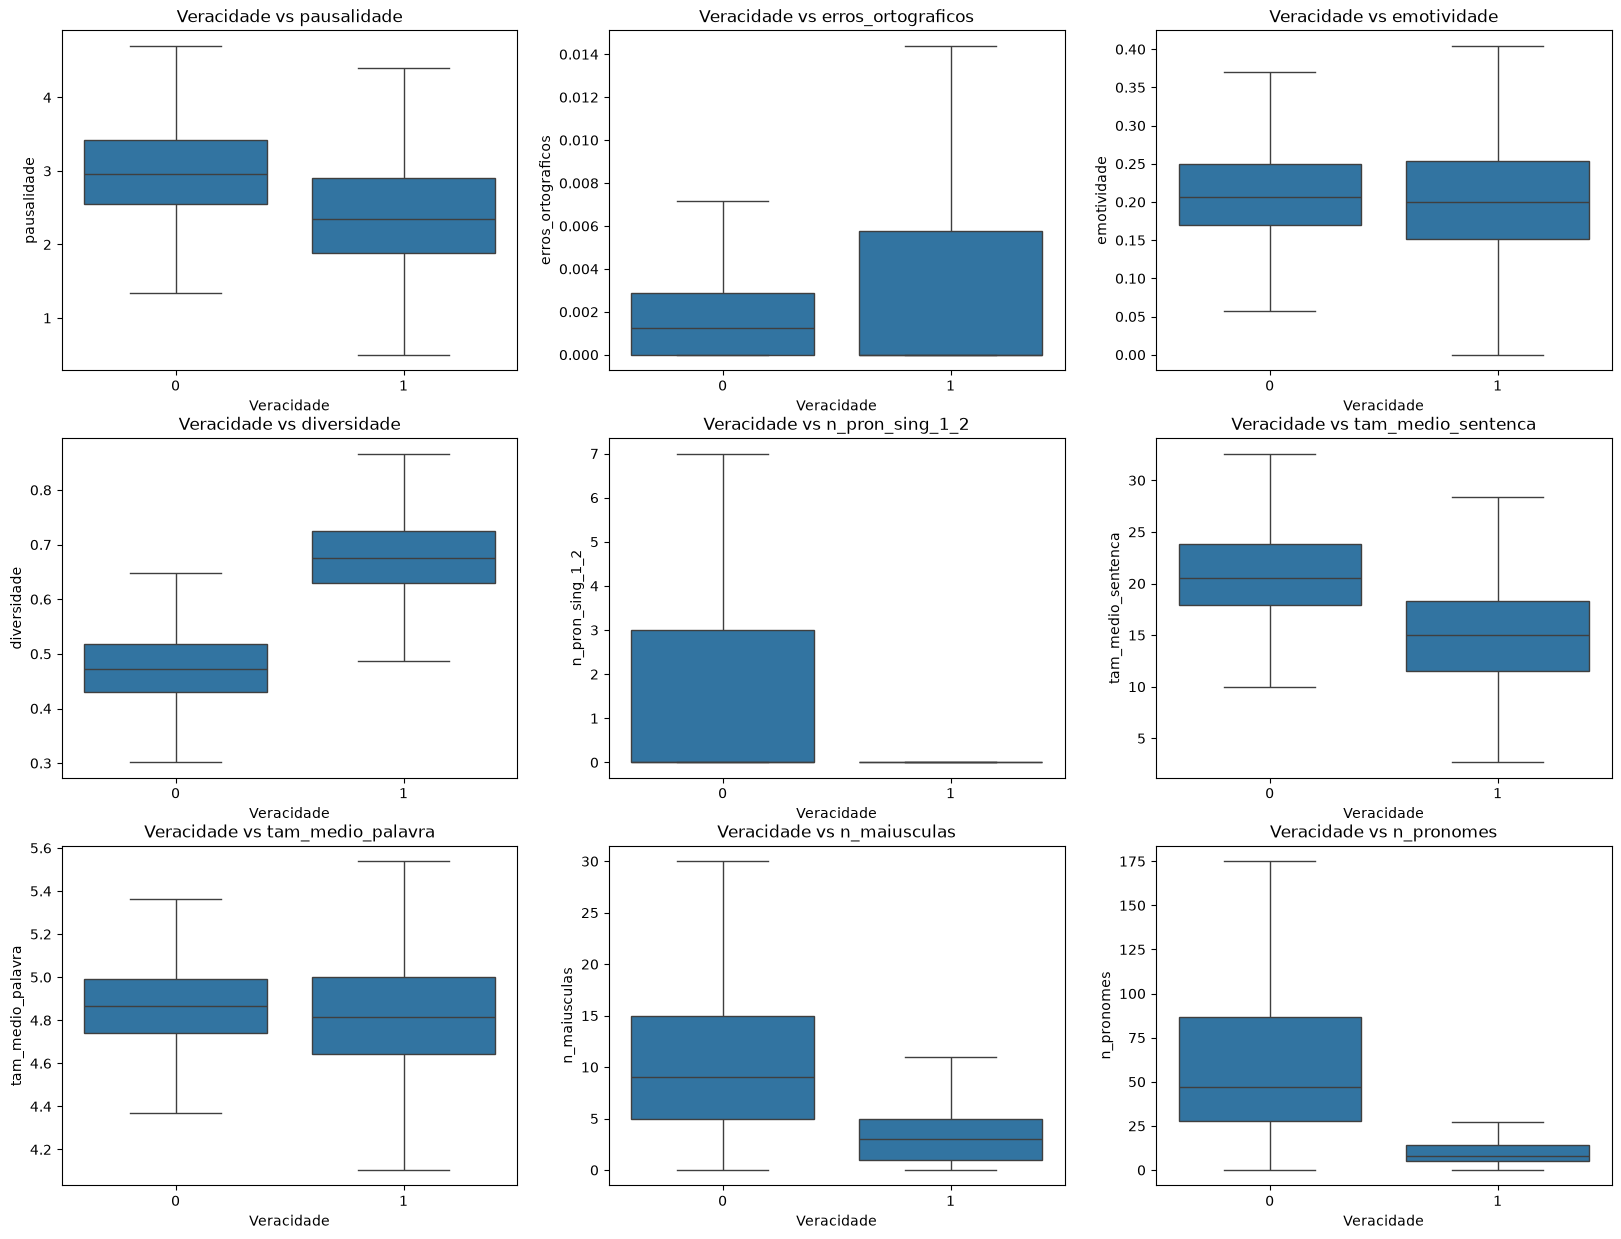

In [77]:
columns = ["pausalidade", "erros_ortograficos", "emotividade", "diversidade", "n_pron_sing_1_2", "tam_medio_sentenca", "tam_medio_palavra", "n_maiusculas", "n_pronomes"]

plt.figure(figsize=(20, 15))
for i, column in enumerate(columns):
    plt.subplot(330 + i + 1)
    sns.boxplot(data=df, x="rotulo", y=column, showfliers=False)
    plt.title(f"Veracidade vs {column}")
    plt.xlabel("Veracidade")
    plt.ylabel(column)

plt.show()

Curiosamente as notícias falsas tem uma maior diversidade média e n_pron_sing_1_2.